<a href="https://colab.research.google.com/github/shubhid3/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP4_AirQuality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
url = ("https://raw.githubusercontent.com/urbanemissions-info/"
"AQI_bulletins/main/data/Processed/AllIndiaBulletins_Master.csv")
df = pd.read_csv(url, low_memory=False)

In [5]:
df.head()

,date,City,No. Stations,Air Quality,Index Value,Prominent Pollutant
0,2015-05-01,Varanasi,NaN,Moderate,157,PM10
1,2015-05-01,Kanpur,NaN,Moderate,175,PM10
2,2015-05-01,Faridabad,NaN,Moderate,173,PM10
3,2015-05-01,Ahmedabad,NaN,Moderate,168,PM2.5
4,2015-05-01,Hyderabad,NaN,Moderate,189,PM2.5


In [6]:
print("shape:", df.shape)
print("=========")
df.info()

shape: (299974, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299974 entries, 0 to 299973
Data columns (total 6 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   date                 299974 non-null  object
 1   City                 299974 non-null  object
 2   No. Stations         299834 non-null  object
 3   Air Quality          299974 non-null  object
 4   Index Value          299974 non-null  int64 
 5   Prominent Pollutant  299973 non-null  object
dtypes: int64(1), object(5)
memory usage: 13.7+ MB


In [7]:
df.isna().sum()

,0
date,0
City,0
No. Stations,140
Air Quality,0
Index Value,0
Prominent Pollutant,1


In [9]:
print("Repeated number of city and date in the row:", df.duplicated(subset=["date", "City"]).sum())
print("=====")
print("Unique city names:", df["City"].nunique())
print("=====")
print("Total times same city name appears", df["City"].value_counts())
print("=====")
first_date = df["date"].min()
last_date = df["date"].max()
print ("First date", first_date,"|" "Last date", last_date)
print("=====")
print(df["Air Quality"].value_counts(dropna=False))
print(df["Air Quality"].value_counts(dropna=False).sum())


Repeated number of city and date in the row: 34
=====
Unique city names: 277
=====
Total times same city name appears City
Delhi              3143
Hyderabad          3132
Bengaluru          3120
Chennai            3075
Lucknow            3056
                   ... 
Barrackpore          27
Karwar               11
Tiruchirappalli       6
Loni_Ghaziabad        2
Jharsuguda            1
Name: count, Length: 277, dtype: int64
=====
First date 2015-05-01 |Last date 2023-12-31
=====
Air Quality
Satisfactory    105251
Moderate         96139
Good             47440
Poor             34641
Very Poor        13969
Severe            2516
Very poor           18
Name: count, dtype: int64
299974


What needs cleaning?
1. Drop duplicate pairs of same city and date since each city per day can have only 1 value of AQI

In [12]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
print(df["date"])
df["Air Quality"] = df["Air Quality"].str.strip().str.upper()
print(df["Air Quality"])
df.drop_duplicates(subset=["date", "City"])
print(df.shape)
df_new = df.drop(columns=["No. Stations"])
print(df_new.shape)
df_new["year"] = df_new["date"].dt.year
df_new["month"] = df_new["date"].dt.month
df_new.head()


0        2015-05-01
1        2015-05-01
2        2015-05-01
3        2015-05-01
4        2015-05-01
            ...    
299969   2023-12-31
299970   2023-12-31
299971   2023-12-31
299972   2023-12-31
299973   2023-12-31
Name: date, Length: 299974, dtype: datetime64[ns]
0             MODERATE
1             MODERATE
2             MODERATE
3             MODERATE
4             MODERATE
              ...     
299969    SATISFACTORY
299970        MODERATE
299971        MODERATE
299972            POOR
299973        MODERATE
Name: Air Quality, Length: 299974, dtype: object
(299974, 8)
(299974, 7)


,date,City,Air Quality,Index Value,Prominent Pollutant,year,month
0,2015-05-01,Varanasi,MODERATE,157,PM10,2015,5
1,2015-05-01,Kanpur,MODERATE,175,PM10,2015,5
2,2015-05-01,Faridabad,MODERATE,173,PM10,2015,5
3,2015-05-01,Ahmedabad,MODERATE,168,PM2.5,2015,5
4,2015-05-01,Hyderabad,MODERATE,189,PM2.5,2015,5


In [13]:
df_new["Index Value"] = pd.to_numeric(df_new["Index Value"], errors="coerce")
print("Air quality statistics for all of India")
print("Median", df_new["Index Value"].median())
print(df_new["Index Value"].describe())
print("=====")
Q1_India = df_new["Index Value"].quantile(0.25)
Q3_India = df_new["Index Value"].quantile(0.75)
IQR_India = Q3_India-Q1_India
print("Q1:", Q1_India, "Q3:", Q3_India, "IQR India:", IQR_India)
print("=====")
India_skew = round(df_new["Index Value"].skew(),2)
print("India skew:", India_skew)
print("=====")
delhi = df_new[df_new["City"] == "Delhi"]
print("Air quality statistics for Delhi")
print("Median", np.median(delhi["Index Value"]))
print(delhi["Index Value"].describe())
print("=====")
Q1_Delhi = delhi["Index Value"].quantile(0.25)
Q3_Delhi = delhi["Index Value"].quantile(0.75)
IQR_Delhi = Q3_Delhi-Q1_Delhi
print("Q1 Delhi:", Q1_Delhi, "Q3 Delhi:", Q3_Delhi, "IQR Delhi:", IQR_Delhi)
print("=====")
Delhi_skew = round(delhi["Index Value"].skew(),2)
print("Delhi skew:", Delhi_skew)
upper_bound = Q3_Delhi + 1.5 * IQR_Delhi
outliers = delhi[delhi["Index Value"] > upper_bound]
print("Number of Delhi outlier days:", len(outliers))



Air quality statistics for all of India
Median 99.0
count    299974.000000
mean        124.694777
std          85.085869
min           3.000000
25%          62.000000
50%          99.000000
75%         162.000000
max         500.000000
Name: Index Value, dtype: float64
=====
Q1: 62.0 Q3: 162.0 IQR India: 100.0
=====
India skew: 1.34
=====
Air quality statistics for Delhi
Median 209.0
count    3143.000000
mean      217.135857
std       104.011419
min        41.000000
25%       127.000000
50%       209.000000
75%       296.000000
max       497.000000
Name: Index Value, dtype: float64
=====
Q1 Delhi: 127.0 Q3 Delhi: 296.0 IQR Delhi: 169.0
=====
Delhi skew: 0.3
Number of Delhi outlier days: 0


AQI Value (Index value) of India is right skewed.

AQI Value (Index value) of Delhi is symmetrically skewed.

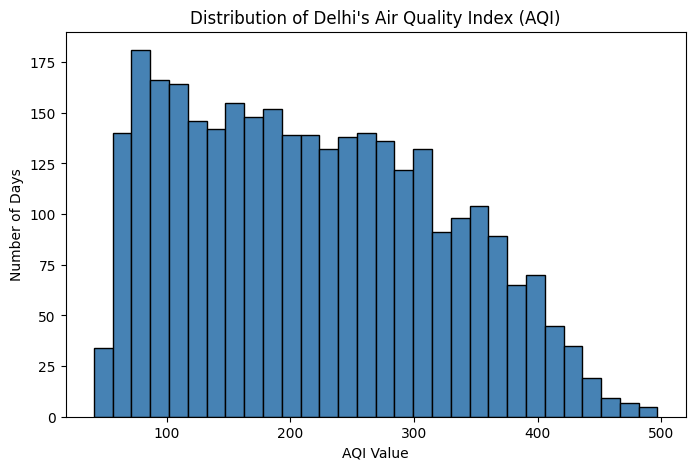

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(delhi["Index Value"].dropna(), bins=30, color="steelblue", edgecolor="black")

plt.title("Distribution of Delhi's Air Quality Index (AQI)")
plt.xlabel("AQI Value")
plt.ylabel("Number of Days")

plt.show()

/tmp/ipykernel_1451/2490177959.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=cities)


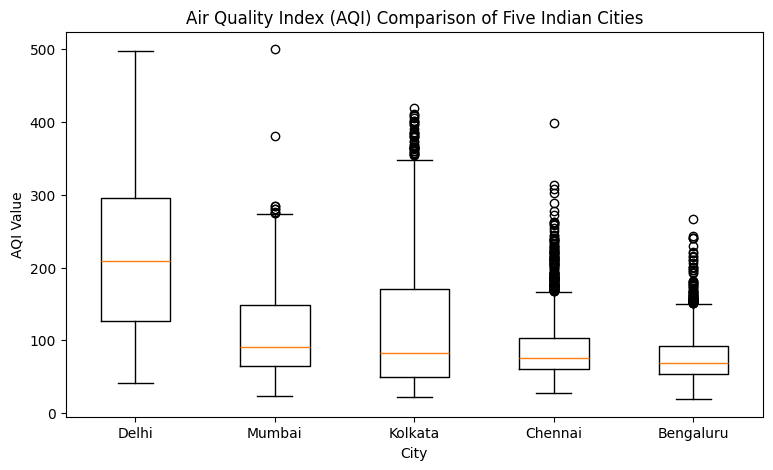

In [15]:
import matplotlib.pyplot as plt

cities = ["Delhi", "Mumbai", "Kolkata", "Chennai", "Bengaluru"]
subset = df_new[df_new["City"].isin(cities)]

data = [subset.loc[subset["City"] == c, "Index Value"].dropna() for c in cities]

plt.figure(figsize=(9, 5))
plt.boxplot(data, labels=cities)

plt.title("Air Quality Index (AQI) Comparison of Five Indian Cities")
plt.xlabel("City")
plt.ylabel("AQI Value")

plt.show()

1. Delhi has the widest spread.

2. Delhi has a median of 209 which is slightly better than mean of 217 - though both can give a rough measure of AQI on a typical day in Delhi.

In [30]:
counts = df_new["City"].value_counts()
print(counts)
print("======")
big = counts[counts >=2000].index
print("Cities with 2,000+ days:", len(big))
print(list(big))
print("======")
big_df = df_new[df_new["City"].isin(big)]
avg_aqi = big_df.groupby("City")["Index Value"].mean().round(1)
print("10 worst cities by AQI")
print(avg_aqi.nlargest(10))
print("======")
print("5 best cities by AQI")
print(avg_aqi.nsmallest(5))

City
Delhi              3143
Hyderabad          3132
Bengaluru          3120
Chennai            3075
Lucknow            3056
                   ... 
Barrackpore          27
Karwar               11
Tiruchirappalli       6
Loni_Ghaziabad        2
Jharsuguda            1
Name: count, Length: 277, dtype: int64
Cities with 2,000+ days: 54
['Delhi', 'Hyderabad', 'Bengaluru', 'Chennai', 'Lucknow', 'Kanpur', 'Navi Mumbai', 'Agra', 'Faridabad', 'Mumbai', 'Varanasi', 'Chandrapur', 'Jodhpur', 'Jaipur', 'Pune', 'Gurugram', 'Muzaffarpur', 'Patna', 'Ahmedabad', 'Panchkula', 'Kolkata', 'Tirupati', 'Gaya', 'Visakhapatnam', 'Howrah', 'Ghaziabad', 'Nashik', 'Noida', 'Rohtak', 'Solapur', 'Thiruvananthapuram', 'Ludhiana', 'Nagpur', 'Amritsar', 'Aurangabad', 'Mandi Gobindgarh', 'Rajamahendravaram', 'Pithampur', 'Kota', 'Udaipur', 'Pali', 'Ajmer', 'Alwar', 'Dewas', 'Thane', 'Jalandhar', 'Ujjain', 'Patiala', 'Mandideep', 'Bhiwadi', 'Haldia', 'Greater Noida', 'Amaravati', 'Khanna']
10 worst cities by AQI
City

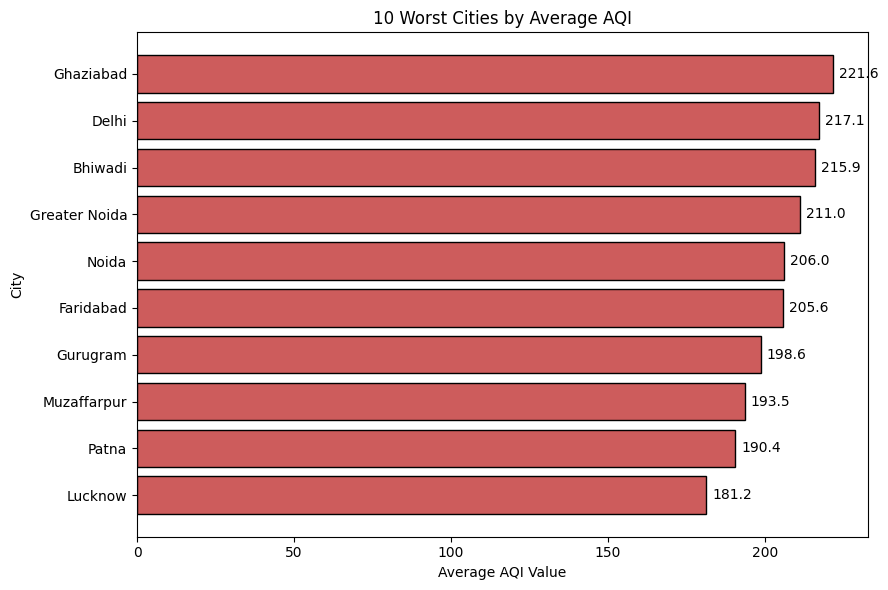

In [31]:
worst10 = avg_aqi.nlargest(10).sort_values()

plt.figure(figsize=(9, 6))
plt.barh(worst10.index, worst10.values, color="indianred", edgecolor="black")

plt.title("10 Worst Cities by Average AQI")
plt.xlabel("Average AQI Value")
plt.ylabel("City")

for i, v in enumerate(worst10.values):
    plt.text(v + 2, i, f"{v:.1f}", va="center")

plt.tight_layout()
plt.show()

In [39]:
df_new["poor_day"] = df_new["Index Value"] > 200
poor_share = (df_new[df_new["City"].isin(big)].groupby("City")["poor_day"].mean().mul(100).round(2))
top10_share = poor_share.nlargest(10)
print("Top 10 cities by share of poor days (%)")
print(top10_share)

Top 10 cities by share of poor days (%)
City
Bhiwadi          54.39
Ghaziabad        52.65
Delhi            52.43
Greater Noida    49.07
Faridabad        46.65
Gurugram         46.26
Noida            46.22
Muzaffarpur      45.11
Patna            42.97
Lucknow          38.55
Name: poor_day, dtype: float64


1. Cities with highest average AQI are same as the cities with largest share of poor days in terms of AQI.
2. These cities share a common background of high industrialisation, denser population, winter smog, and crop residue burning which leads to poor AQI.

month
1     316.1
2     254.7
3     196.1
4     209.6
5     204.9
6     172.4
7     108.6
8     103.4
9     123.9
10    242.9
11    348.6
12    334.9
Name: Index Value, dtype: float64


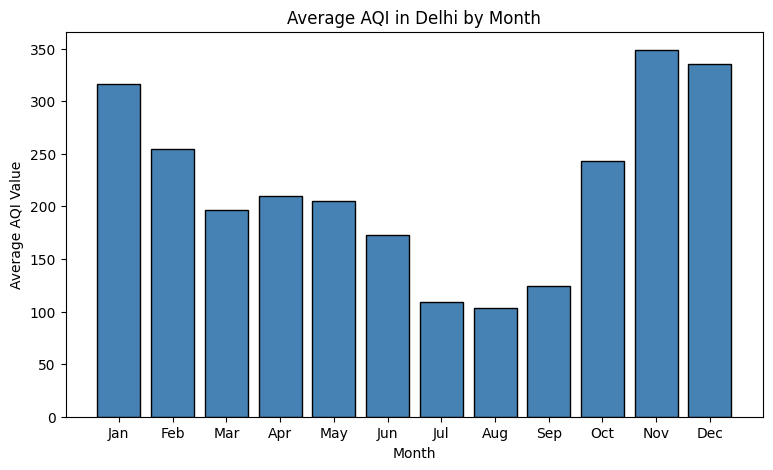

In [47]:
delhi = df_new[df_new["City"] == "Delhi"].copy()
delhi["month"] = delhi["date"].dt.month

monthly_avg_delhi = delhi.groupby("month")["Index Value"].mean().round(1)
print(monthly_avg_delhi)
print("======")

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
plt.figure(figsize=(9, 5))
plt.bar(monthly_avg_delhi.index, monthly_avg_delhi.values,
        color="steelblue", edgecolor="black")

plt.xticks(range(1, 13), month_names)
plt.title("Average AQI in Delhi by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI Value")

plt.show()

year
2015    229.5
2016    256.4
2017    227.5
2018    225.4
2019    214.6
2020    185.1
2021    208.6
2022    209.2
2023    203.6
Name: Index Value, dtype: float64
=====


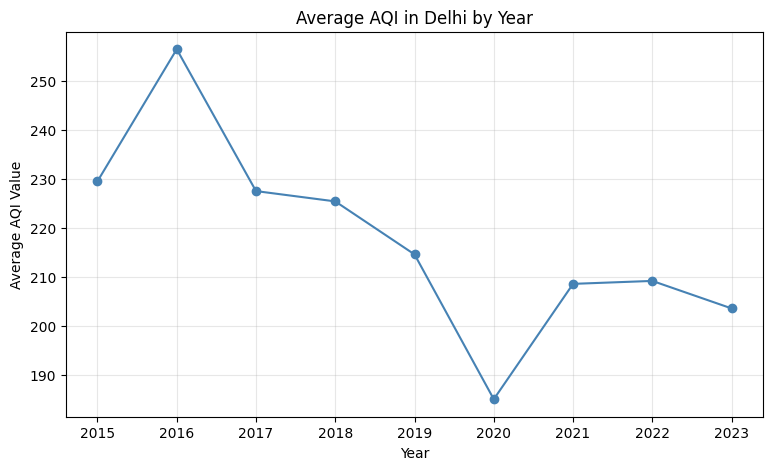

In [61]:
delhi = df_new[df_new["City"] == "Delhi"].copy()
delhi["year"] = delhi["date"].dt.year
yearly_avg_Delhi = delhi.groupby("year")["Index Value"].mean().round(1)
print(yearly_avg_Delhi)

print("=====")

plt.figure(figsize=(9, 5))
plt.plot(yearly_avg_Delhi.index, yearly_avg_Delhi.values, marker="o", color="steelblue")

plt.title("Average AQI in Delhi by Year")
plt.xlabel("Year")
plt.ylabel("Average AQI Value")
plt.xticks(yearly_avg_Delhi.index)
plt.grid(alpha=0.3)

plt.show()

In [60]:
import plotly.express as px

yearly_avg_Delhi = delhi.groupby("year")["Index Value"].mean().round(1).reset_index()
yearly_avg_Delhi.columns = ["year", "avg_aqi"]

fig = px.line(
    yearly_avg_Delhi,
    x="year",
    y="avg_aqi",
    markers=True,
    title="Average AQI in Delhi by Year",
    labels={"year": "Year", "avg_aqi": "Average AQI Value"},
)
fig.update_axes(dtick=1)  # one tick per year
fig.show()

1. November, December and January are the worst months in terms of air quality of Delhi.
2. Delhi's yearly average shows improvement after 2019 (after the clean air programme began in 2019).